# Customizing mating in `popstatgensim`

This notebook is a tour of the **mating model** — what knobs exist, what each one does, and
how they interact. It is aimed at someone who wants to *use* the simulator and does not yet
know what is available.

It is **not** a verification of the assortative-mating theory. That lives in
`popstatgenwriteups/writeups/statistical_genetics/relative_covariance/` (the derivations) and
its `simulation/` subtree (the notebooks that check them against simulation).

## The knobs

All of these are `PopulationParams` fields, settable via `pop.set_params(...)`:

| parameter | what it controls |
|---|---|
| `mate_q` | survival array: `q_k` = fraction of individuals with **at least** `k` mates |
| `mate_pmf` | alternative input: `p_k` = fraction with **exactly** `k` mates (converted internally) |
| `offspring_f` | pmf of offspring per mate pair |
| `n_offspring_dist` | allocation mode when `offspring_f` is not given |
| `forbid_mate_cycles` | forest constraint on the mate graph |
| `AM_r`, `AM_trait`, `AM_type` | the assortment itself |

## The two independent dials

The thing most worth internalizing up front: **`mate_q` and `offspring_f` are separate dials**,
and they both move the sibship mixture. `mate_q` controls how many *mates* an individual has;
`offspring_f` controls how many *offspring* a mate pair has. You can hold one fixed and change
the other.

They are linked by exactly one constraint. With `kappa = sum_k q_k` mean mates per individual,
there are `U = kappa*N/2` mate pairs, and those pairs must produce `N` offspring — so

$$\text{mean}(f) \;=\; \frac{2}{\kappa}$$

and that is the **only** constraint on `offspring_f`. Its shape is otherwise free.

Everything below uses small populations (N in the hundreds, M = 40) so the notebook runs
quickly; each section states what it uses. Nothing here needs N in the thousands.

## Setup

Two helpers used throughout. `sib_pair_counts` counts **pairs**, not individuals — a sibship of
`n` full sibs contributes `C(n,2)` full-sib pairs, which is why the offspring distribution
matters so much later.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

from popstatgensim import Population, GeneticEffect
from popstatgensim.simulation.mating import (
    normalize_survival, survival_from_pmf, mean_n_mates, mean_offspring_per_pair,
    offspring_pmf, pmf_mean, pmf_dispersion, validate_offspring_pmf,
    predict_halfsib_fullsib_ratio, build_mate_graph, measure_mate_chain_correlation,
)
from popstatgensim.pedigree.graph import PedigreeGraph
from popstatgensim.pedigree.relate import enumerate_class, VALID_CLASS_SPECS

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (6.2, 3.6), "font.size": 9})


def make_pop(N=500, M=40, seed=0, h2=0.5, **params):
    """A small population with one additive trait, ready to mate."""
    np.random.seed(seed)
    pop = Population(N=N, M=M, seed=seed)
    pop.assign_sex()
    pop.add_trait(
        name="y",
        effects={"A": GeneticEffect(var_indep=h2, M=M, M_causal=M, name="A")},
        var_Eps=1.0 - h2,
    )
    settings = dict(AM_r=0.5, AM_trait="y", AM_type="phenotypic", keep_past_generations=1)
    settings.update(params)
    pop.set_params(**settings)
    return pop


def sib_pair_counts(pop):
    """(full-sib pairs, half-sib pairs) among the current generation.

    Counts PAIRS: a sibship of n full sibs contributes C(n,2) full-sib pairs.
    """
    par = np.asarray(pop.relations["parents"])
    by_parent = defaultdict(list)
    for i in range(pop.N):
        for p in par[i]:
            if p >= 0:
                by_parent[int(p)].append(i)
    full = half = 0
    seen = set()
    for group in by_parent.values():
        for a in range(len(group)):
            for b in range(a + 1, len(group)):
                i, j = group[a], group[b]
                key = (i, j) if i < j else (j, i)
                if key in seen:
                    continue
                seen.add(key)
                shared = len(set(par[i]) & set(par[j]) - {-1})
                if shared == 2:
                    full += 1
                elif shared == 1:
                    half += 1
    return full, half

---
## 1. Monogamy is the special case, not the default that was replaced

`mate_q = [1]` means "everyone has at least 1 mate, nobody has 2" — i.e. monogamy. Pair it with
a deterministic `offspring_f` of mean 2 and you get exactly the old behaviour: every sibling pair
is a **full** sibling pair, there are no half-sibs, and population size is preserved exactly.

Worth showing first because it anchors everything else: the new model is a *generalization*, and
you can always dial back to where you were. **N = 500, M = 40, one generation.**

In [2]:
q = normalize_survival(q=[1.0])
f = offspring_pmf("deterministic", mean_offspring_per_pair(q))

print(f"kappa (mean mates/individual) = {mean_n_mates(q):.2f}")
print(f"required mean(f) = 2/kappa    = {mean_offspring_per_pair(q):.2f}")
print(f"offspring pmf f               = {np.round(f[:4], 3)}  (all pairs have exactly 2)")

pop = make_pop(N=500, mate_q=[1.0], offspring_f=f)
pop.simulate_generations(1)

full, half = sib_pair_counts(pop)
edges = pop.past[1].relations["mate_edges"]
n_mates = np.bincount(edges.ravel(), minlength=500)

print(f"\npopulation size preserved     : {pop.N == 500}")
print(f"mate pairs U                  : {edges.shape[0]}  (expected kappa*N/2 = {int(1.0*500/2)})")
print(f"mates per individual          : {sorted(set(n_mates.tolist()))}  (everyone has exactly one)")
print(f"full-sib pairs                : {full}")
print(f"half-sib pairs                : {half}   <- monogamy cannot produce these")

kappa (mean mates/individual) = 1.00
required mean(f) = 2/kappa    = 2.00
offspring pmf f               = [0. 0. 1. 0.]  (all pairs have exactly 2)

population size preserved     : True
mate pairs U                  : 250  (expected kappa*N/2 = 250)
mates per individual          : [1]  (everyone has exactly one)
full-sib pairs                : 250
half-sib pairs                : 0   <- monogamy cannot produce these


---
## 2. The non-monogamy dial: `mate_q`

`mate_q = [1, q2]` gives a fraction `q2` of the population a **second** mate. Mating happens in
*rounds*: round 1 matches everyone, round `k` matches a random sex-balanced fraction `q_k` again.

The sibship mixture follows a design formula,

$$\frac{\text{half-sib pairs}}{\text{full-sib pairs}} \;\approx\; \frac{2\,E[K(K-1)]}{\kappa\,D}$$

which for the two-state Poisson case reduces to `4*q2/(1+q2)`. `predict_halfsib_fullsib_ratio`
evaluates it.

**It is an approximation**, meant for aiming parameters at a target mixture — not a law. The plot
below shows measured against predicted so you can see how good it is (close, and it drifts a
little low at large `q2`). **N = 500, M = 40, one generation per point.**

In [3]:
q2_values = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
rows = []
for q2 in q2_values:
    qq = normalize_survival(q=[1.0, q2]) if q2 > 0 else normalize_survival()
    ff = offspring_pmf("poisson", mean_offspring_per_pair(qq))
    p = make_pop(N=500, seed=1, mate_q=(None if q2 == 0 else [1.0, q2]), offspring_f=ff)
    p.simulate_generations(1)
    fu, ha = sib_pair_counts(p)
    edges = p.past[1].relations["mate_edges"]
    rows.append(dict(q2=q2, kappa=mean_n_mates(qq), U=edges.shape[0],
                     max_mates=int(np.bincount(edges.ravel(), minlength=500).max()),
                     full=fu, half=ha,
                     measured=(ha / fu if fu else np.nan),
                     predicted=predict_halfsib_fullsib_ratio(qq, ff)))

print(f"{'q2':>5}{'kappa':>7}{'U':>6}{'maxmates':>10}{'full':>7}{'half':>7}{'measured':>10}{'formula':>9}")
for r in rows:
    print(f"{r['q2']:>5.1f}{r['kappa']:>7.2f}{r['U']:>6}{r['max_mates']:>10}"
          f"{r['full']:>7}{r['half']:>7}{r['measured']:>10.3f}{r['predicted']:>9.3f}")

   q2  kappa     U  maxmates   full   half  measured  formula
  0.0   1.00   250         1    511      0     0.000    0.000
  0.2   1.20   300         2    423    268     0.634    0.667
  0.4   1.40   350         2    361    380     1.053    1.143
  0.6   1.60   400         2    316    472     1.494    1.500
  0.8   1.80   450         2    283    494     1.746    1.778
  1.0   2.00   499         2    255    483     1.894    2.000


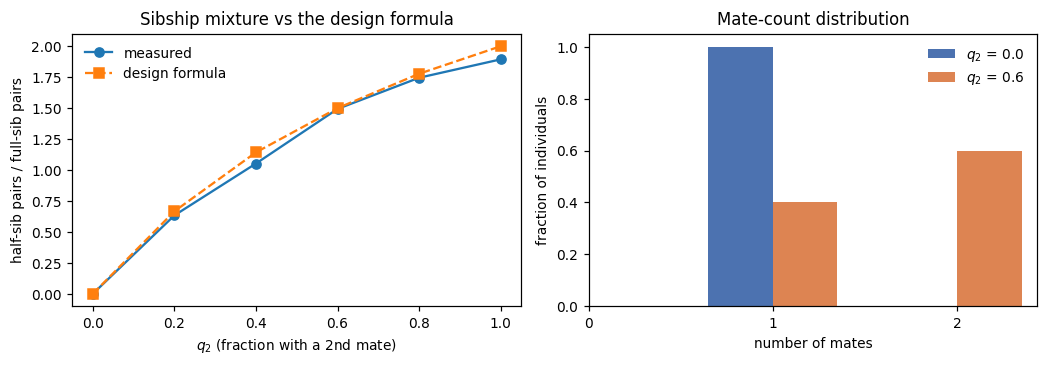

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.4))

ax1.plot([r["q2"] for r in rows], [r["measured"] for r in rows], "o-", label="measured")
ax1.plot([r["q2"] for r in rows], [r["predicted"] for r in rows], "s--", label="design formula")
ax1.set_xlabel("$q_2$ (fraction with a 2nd mate)")
ax1.set_ylabel("half-sib pairs / full-sib pairs")
ax1.set_title("Sibship mixture vs the design formula")
ax1.legend(frameon=False)

width = 0.35
for k, (q2, colour) in enumerate([(0.0, "#4C72B0"), (0.6, "#DD8452")]):
    qq = normalize_survival(q=[1.0, q2]) if q2 > 0 else normalize_survival()
    ff = offspring_pmf("poisson", mean_offspring_per_pair(qq))
    p = make_pop(N=500, seed=1, mate_q=(None if q2 == 0 else [1.0, q2]), offspring_f=ff)
    p.simulate_generations(1)
    counts = np.bincount(p.past[1].relations["mate_edges"].ravel(), minlength=500)
    vals, freqs = np.unique(counts, return_counts=True)
    ax2.bar(vals + (k - 0.5) * width, freqs / 500, width=width,
            label=f"$q_2$ = {q2}", color=colour)
ax2.set_xlabel("number of mates")
ax2.set_ylabel("fraction of individuals")
ax2.set_title("Mate-count distribution")
ax2.set_xticks([0, 1, 2])
ax2.legend(frameon=False)

plt.tight_layout()
plt.show()

---
## 3. The second dial: `offspring_f`, at *fixed* `kappa`

Here is the part that surprises people. Hold `kappa` fixed — same number of mates, same number of
mate pairs, same mean offspring per pair — and change only the **shape** of `offspring_f`. The
sibship mixture moves a lot.

The reason is convexity. A mate pair with `n` offspring contributes `C(n,2) = n(n-1)/2` full-sib
pairs, which is convex in `n`. So spreading the same total offspring **less evenly** across pairs
produces *more* full-sib pairs, even though the mean is unchanged. `pmf_dispersion` reports
`D = (E[n^2] - m)/m^2`, which is the quantity the design formula uses: `D = 1` for Poisson,
`1 - 1/m` for deterministic counts.

Below, `D` ranges from 0.32 to 1.78 and full-sib pairs go from ~100 to ~590 — at identical
`kappa`. **N = 500, M = 40, `kappa` = 1.6 throughout.**

In [5]:
q = normalize_survival(q=[1.0, 0.6])
m = mean_offspring_per_pair(q)
print(f"kappa = {mean_n_mates(q):.2f}, so every f below must have mean 2/kappa = {m:.4f}\n")

shapes = [("deterministic", {}), ("poisson", {}),
          ("zero_inflated_poisson", dict(f_zero=0.3)),
          ("negative_binomial", dict(overdispersion=2.0))]

print(f"{'offspring_f':<24}{'mean':>8}{'D':>7}{'f_0':>7}{'full':>7}{'half':>7}{'ratio':>8}{'formula':>9}")
f_shapes = {}
for name, kw in shapes:
    ff = offspring_pmf(name, m, **kw)
    f_shapes[name] = ff
    p = make_pop(N=500, seed=2, mate_q=[1.0, 0.6], offspring_f=ff)
    p.simulate_generations(1)
    fu, ha = sib_pair_counts(p)
    print(f"{name:<24}{pmf_mean(ff):>8.4f}{pmf_dispersion(ff):>7.3f}{ff[0]:>7.3f}"
          f"{fu:>7}{ha:>7}{ha/fu:>8.3f}{predict_halfsib_fullsib_ratio(q, ff):>9.3f}")

print("\nMore offspring-count variance (higher D) -> MORE full-sib pairs, at identical kappa.")

kappa = 1.60, so every f below must have mean 2/kappa = 1.2500

offspring_f                 mean      D    f_0   full   half   ratio  formula
deterministic             1.2500  0.320  0.000    103    470   4.563    4.688
poisson                   1.2500  1.000  0.287    315    446   1.416    1.500
zero_inflated_poisson     1.2500  1.429  0.417    460    502   1.091    1.050
negative_binomial         1.2500  1.782  0.420    586    486   0.829    0.842

More offspring-count variance (higher D) -> MORE full-sib pairs, at identical kappa.


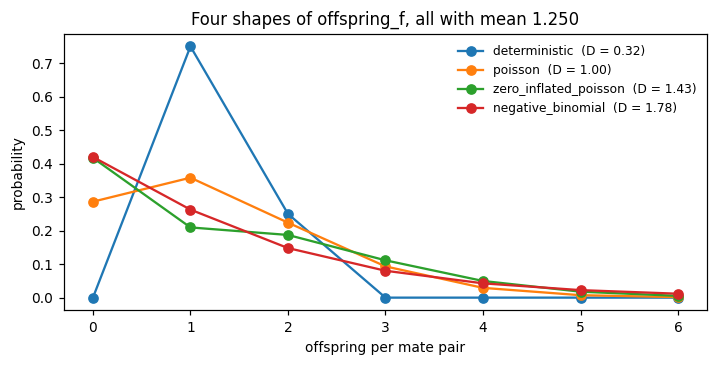

In [6]:
fig, ax = plt.subplots(figsize=(6.6, 3.4))
n_max = 7
for name, _ in shapes:
    ff = f_shapes[name]
    ax.plot(np.arange(min(n_max, len(ff))), ff[:n_max], "o-",
            label=f"{name}  (D = {pmf_dispersion(ff):.2f})")
ax.set_xlabel("offspring per mate pair")
ax.set_ylabel("probability")
ax.set_title(f"Four shapes of offspring_f, all with mean {m:.3f}")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### The mean constraint is enforced

`mean(f) = 2/kappa` is the one thing `offspring_f` must satisfy. Supply anything else and
`validate_offspring_pmf` refuses rather than quietly rescaling — a silently-rescaled pmf would
give you a population of the wrong size or a sibship mixture you did not ask for.

In [7]:
try:
    validate_offspring_pmf(offspring_pmf("poisson", 3.0), kappa=mean_n_mates(q))
except ValueError as err:
    print("ValueError:", err)

ValueError: mean(f) must equal 2/kappa = 1.25 (D-0005), got 3. This is the only constraint on f; adjust its shape to hit the mean.


---
## 4. Childless mate pairs, and why they matter

`f_0` is the fraction of mate pairs with **no** offspring. It needs no separate parameter — it is
just the zero bin of `offspring_f`, which is why `zero_inflated_poisson` takes an `f_zero`
argument.

The non-obvious part: **childless pairs still assort, and still sit on mate chains.** They
contribute nothing to the sibship counts, but they are still edges in the mate graph — which is
exactly what makes the mate-chain-only relationship classes (`parent_parent`, and
`married_couple_parents`) observable. If childless pairs were dropped, those classes would be
systematically undercounted.

**N = 500, M = 40, one generation.**

In [8]:
print(f"{'f_0 requested':>14}{'f_0 realized':>14}{'mate pairs':>12}{'childless':>11}{'full':>7}{'half':>7}")
for f_zero in (0.0, 0.2, 0.4):
    ff = (offspring_pmf("poisson", m) if f_zero == 0.0
          else offspring_pmf("zero_inflated_poisson", m, f_zero=f_zero))
    p = make_pop(N=500, seed=4, mate_q=[1.0, 0.6], offspring_f=ff)
    p.simulate_generations(1)
    fu, ha = sib_pair_counts(p)
    parent_pop = p.past[1]
    edges = parent_pop.relations["mate_edges"]
    # a mate pair is childless if no offspring lists both of its members as parents
    par = np.asarray(p.relations["parents"])
    used = {(min(a, b), max(a, b)) for a, b in par if a >= 0 and b >= 0}
    childless = sum(1 for a, b in edges if (min(a, b), max(a, b)) not in used)
    print(f"{f_zero:>14.2f}{ff[0]:>14.3f}{edges.shape[0]:>12}{childless:>11}{fu:>7}{ha:>7}")

print("\nChildless pairs remain edges in the mate graph, so parent--parent and")
print("parents-of-a-married-couple stay observable even as f_0 rises.")

 f_0 requested  f_0 realized  mate pairs  childless   full   half


          0.00         0.287         400        125    338    478
          0.20         0.368         400        148    401    474
          0.40         0.475         400        199    562    505

Childless pairs remain edges in the mate graph, so parent--parent and
parents-of-a-married-couple stay observable even as f_0 rises.


---
## 5. Which relationship classes each setting makes reachable

The payoff section: pick parameters for the classes you actually need.

Under monogamy, **half-sibs and step-sibs simply do not exist** — five of the eleven rows of the
writeup's relationship table are unreachable. Turning on a second mate opens them up, and raising
`q2` further trades full-sibs (and their descendants — avuncular, cousins) for the mate-chain
classes.

`enumerate_class` generates each class constructively from local structure, so this costs
`O(instances)` rather than classifying all `N^2` pairs. **N = 500, M = 40, three generations, so
the graph spans 4 retained generations (2000 individuals).**

In [9]:
settings = [
    ("monogamy [1]", dict(mate_q=[1.0])),
    ("q2 = 0.6", dict(mate_q=[1.0, 0.6])),
    ("3 rounds [1, 1, .5]", dict(mate_q=[1.0, 1.0, 0.5])),
]

counts = {}
for label, kw in settings:
    qq = normalize_survival(q=kw["mate_q"])
    ff = offspring_pmf("poisson", mean_offspring_per_pair(qq))
    p = make_pop(N=500, seed=3, keep_past_generations=3, offspring_f=ff, **kw)
    p.simulate_generations(3)
    g = PedigreeGraph.from_population(p)
    counts[label] = {s: len(list(enumerate_class(g, s, limit=200000)))
                     for s in VALID_CLASS_SPECS}

print(f"{'class':<26}" + "".join(f"{lab:>22}" for lab, _ in settings))
for spec in VALID_CLASS_SPECS:
    print(f"{spec:<26}" + "".join(f"{counts[lab][spec]:>22,}" for lab, _ in settings))

class                               monogamy [1]              q2 = 0.6   3 rounds [1, 1, .5]
full_sibs                                  1,495                   969                   739
half_sibs                                      0                 1,456                 1,483
step_sibs                                      0                 1,244                 1,542
parent_offspring                           3,000                 3,000                 3,000
grandparent                                4,000                 4,000                 4,000
avuncular                                  4,118                 2,521                 1,867
first_cousins                              8,434                 4,956                 3,719
parent_parent                                750                 1,200                 1,497
married_couple_parents                     2,000                 3,200                 3,992


**Step-step siblings are the exception.** They need a mate chain of `N_mu = 4` — four matings
linking the two probands' parents — and that is effectively unsampleable from a random population
at any feasible `N`. They are verified instead on hand-built pedigrees (see
`tests/test_relate.py::test_sibling_ladder_on_hand_built_pedigrees`). Better to know that now than
to spend compute looking for them.

The four sibling classes differ only in how many matings separate the parents:

| class | `N_mu` |
|---|---|
| full siblings | 1 |
| half siblings | 2 |
| step siblings | 3 |
| step-step siblings | 4 |

---
## 6. The mate graph itself

The mate graph replaces the old length-`N` `relations['spouses']` array, which structurally could
not hold a second mate.

> **`relations['spouses']` is lossy under non-monogamy** — it keeps only each individual's *first*
> mate (D-0013). Read `relations['mate_edges']`, a `(U, 2)` array of `(maternal, paternal)` index
> pairs. `relations['mate_round_id']` records which matching round produced each edge. Both live on
> the generation that *did* the mating, i.e. `pop.past[1]` after one step.

`forbid_mate_cycles` enforces the forest constraint, which is what makes the mating chain between
any two individuals *unique*. With it off, cycles appear — but only `O(log N)` of them, because a
union of matchings behaves like a random permutation rather than a random graph. **N = 600.**

In [10]:
N = 600
rng = np.random.default_rng(0)
sex = np.zeros(N, dtype=int); sex[N // 2:] = 1; sex = rng.permutation(sex)
y = rng.normal(size=N); y = (y - y.mean()) / y.std()

for forbid in (True, False):
    g = build_mate_graph(N, sex, y, rho_y=0.5, q=[1.0, 1.0], forbid_cycles=forbid)
    print(f"forbid_mate_cycles={str(forbid):<6}  U={g.U}  cycles={g.count_cycles():>2}  "
          f"max mates={g.n_mates().max()}  unrepairable pairs dropped={g.n_dropped}")
print(f"\nlog(N) = {np.log(N):.1f}, so the cycle count with the constraint off is O(log N) as expected.")
print("Dropped pairs are rare (<0.1%) and recorded rather than silently absorbed.")

forbid_mate_cycles=True    U=599  cycles= 0  max mates=2  unrepairable pairs dropped=1
forbid_mate_cycles=False   U=600  cycles= 4  max mates=2  unrepairable pairs dropped=0

log(N) = 6.4, so the cycle count with the constraint off is O(log N) as expected.
Dropped pairs are rare (<0.1%) and recorded rather than silently absorbed.


In [11]:
# mate_edges vs the lossy spouses array, on the same generation
p = make_pop(N=500, seed=5, mate_q=[1.0, 0.8],
             offspring_f=offspring_pmf("poisson",
                                       mean_offspring_per_pair(normalize_survival(q=[1.0, 0.8]))))
p.simulate_generations(1)
parent = p.past[1]

edges = parent.relations["mate_edges"]
spouse = np.asarray(parent.relations["spouses"], dtype=np.int32)
n_spouse_pairs = int(np.sum((spouse >= 0) & (np.arange(parent.N) < spouse)))

print(f"mate_edges  : {edges.shape[0]} pairs   <- all of them")
print(f"spouses     : {n_spouse_pairs} pairs   <- first mate only, {edges.shape[0] - n_spouse_pairs} missing")
print(f"rounds used : {sorted(set(parent.relations['mate_round_id'].tolist()))}")

mate_edges  : 450 pairs   <- all of them
spouses     : 250 pairs   <- first mate only, 200 missing
rounds used : [0, 1]


---
## 7. Assortment interacting with non-monogamy

Each matching round realizes the target `rho_y` on its own participating subset. But round `k > 1`
draws from a **smaller pool** — `q_k * N / 2` rather than `N / 2` — and the constraint rejections
concentrate there, so its realized `rho_y` attenuates slightly.

The effect is small and scales with pool size: about 4% at `q2 = 0.3`, essentially zero by
`q2 >= 0.6`. It matters because it **compounds along a mate chain**: a mate-chain prediction of
distance `n` carries `rho_y^(n-1)`, so a 4% per-round shortfall is ~12% by `N_mu = 4`.

Hence D-0014: mate-chain predictions are evaluated at the **product of the measured per-round
`rho_y`**, not a power of a pooled one. `predicted_cov` takes `rho_y_by_round` for this, and
**raises** rather than silently pooling when a chain crosses rounds.

**The practical advice is simpler than the rule: use `q2 >= 0.6` and the distinction is moot.**
**N = 600, 12 replicates per point.**

In [12]:
print(f"{'q2':>5}{'rho_y round 1':>15}{'rho_y round 2':>15}{'r2/r1':>9}"
      f"{'Corr(y_j,y_k)':>16}{'rho_y^2':>10}")
atten = []
for q2 in (0.3, 0.6, 1.0):
    r1s, r2s, corrs, sqs = [], [], [], []
    for r in range(12):
        rr = np.random.default_rng(100 + r); np.random.seed(100 + r)
        sx = np.zeros(N, dtype=int); sx[N // 2:] = 1; sx = rr.permutation(sx)
        yy = rr.normal(size=N); yy = (yy - yy.mean()) / yy.std()
        gg = build_mate_graph(N, sx, yy, rho_y=0.5, q=[1.0, q2])
        out = measure_mate_chain_correlation(gg, yy)
        r1s.append(out["round_rho_y"][0]); r2s.append(out["round_rho_y"][1])
        corrs.append(out["corr"]); sqs.append(out["rho_y_squared"])
    ratio = np.mean(r2s) / np.mean(r1s)
    atten.append((q2, ratio))
    print(f"{q2:>5.1f}{np.mean(r1s):>15.4f}{np.mean(r2s):>15.4f}{ratio:>9.4f}"
          f"{np.nanmean(corrs):>16.4f}{np.mean(sqs):>10.4f}")

print("\nCorr(y_j, y_k) is the correlation between one individual's TWO mates.")
print("The rounds mechanism predicts rho_y^2 there, and it holds -- which is what makes")
print("the mate-chain formulas testable rather than imposed.")

   q2  rho_y round 1  rho_y round 2    r2/r1   Corr(y_j,y_k)   rho_y^2
  0.3         0.4949         0.4719   0.9535          0.2412    0.2410
  0.6         0.4949         0.4853   0.9805          0.2197    0.2414
  1.0         0.4949         0.4931   0.9962          0.2279    0.2446

Corr(y_j, y_k) is the correlation between one individual's TWO mates.
The rounds mechanism predicts rho_y^2 there, and it holds -- which is what makes
the mate-chain formulas testable rather than imposed.


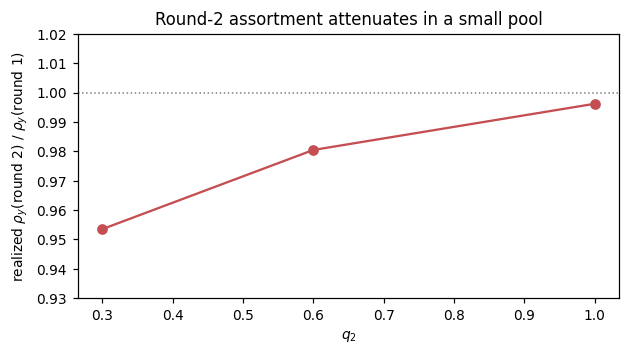

In [13]:
fig, ax = plt.subplots(figsize=(5.8, 3.3))
ax.plot([a[0] for a in atten], [a[1] for a in atten], "o-", color="#C44E52")
ax.axhline(1.0, ls=":", c="0.5", lw=1)
ax.set_xlabel("$q_2$")
ax.set_ylabel(r"realized $\rho_y$(round 2) / $\rho_y$(round 1)")
ax.set_title("Round-2 assortment attenuates in a small pool")
ax.set_ylim(0.93, 1.02)
plt.tight_layout()
plt.show()

---
## Picking parameters: a short guide

| you want | set |
|---|---|
| the old monogamous behaviour | `mate_q=[1]`, `offspring_f` deterministic with mean 2 |
| half-sibs and step-sibs | `mate_q=[1, q2]` with `q2 > 0` |
| more of the mate-chain classes | raise `q2` |
| more full-sib pairs at fixed `kappa` | a **higher-variance** `offspring_f` (negative binomial) |
| fewer full-sib pairs at fixed `kappa` | a **lower-variance** `offspring_f` (deterministic) |
| an explicit childless fraction | `offspring_f=offspring_pmf('zero_inflated_poisson', m, f_zero=...)` |
| unique mating chains (usual) | `forbid_mate_cycles=True` (the default) |
| assortment that needs no per-round bookkeeping | `q2 >= 0.6` |

Two reminders that cause silent wrong numbers rather than errors, so they are worth repeating:

- **Read `relations['mate_edges']`, not `relations['spouses']`**, under non-monogamy. The latter
  keeps only first mates (D-0013). `get_spouse_corr` now raises rather than returning a
  first-mate-only figure; use `estimation.measure_mate_correlations`.
- **`mean(offspring_f)` must be `2/kappa`.** It is validated, so you will be told — but if you
  change `mate_q` and forget to rebuild `offspring_f`, that is the error you will see.

### Where to go next

- **The theory**: `popstatgenwriteups/writeups/statistical_genetics/relative_covariance/`
- **Verification against it**: that writeup's `simulation/` subtree
- **The relatedness layer**: `popstatgensim.pedigree.relate` — `relate()` for a pair,
  `enumerate_class()` for a class, `predicted_cov()` for the writeup's closed form